In [9]:
# Training name
training_name = 'SQAutoEncoder_SlimConv2D_80e_2bit'

# Gaussian noise parameters
NOISE_MU = 0.0
NOISE_SIGMA = 80.0 # e-

# Precision of input data
N_BITS = 2

In [10]:
# IMPORTS ---------------------------------------------------------------------

import warnings
warnings.filterwarnings("ignore")

import os, subprocess
from pathlib import Path
import random

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
colors = list(mcolors.TABLEAU_COLORS.keys())

from models import *
from plotting import *
from OptimizedDataGenerator_v2 import OptimizedDataGenerator

In [11]:
# DATA ---------------------------------------------------------------------

dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/"

dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'test_contained/')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val",'3srCI_16x16_'+str(int(NOISE_SIGMA))+'eN_raw_slim')

In [12]:
seeds = grep('Seed','log_'+training_name+'.txt')
print("Seeds = ", seeds)

fingerprints = grep('Fingerprint','log_'+training_name+'.txt')
print("Fingerprints = ", fingerprints)
    
# residuals = {}
thresholds = {}
best_epoch = {}

# BEGIN LOOP ---------------------------------------------------------------------
for i in range(len(fingerprints)):

    base_dir = '/uscms/home/bweiss/nobackup/smart-pixels/SQAutoEncoder_models/model-'+fingerprints[i]+'-'+training_name+'-checkpoints/'
    
    if not os.path.exists(base_dir):
        base_dir = '/uscms/home/bweiss/nobackup/smart-pixels/SQAutoEncoder_models/model-'+fingerprints[i]+'-'+'SQAutoEncoder_SlimConv2D_80e_2bit_2'+'-checkpoints/'
        if not os.path.exists(base_dir):
            print("Fingerprint " + fingerprints[i] + " not found")
            continue
        
    # checkpoint_dir = base_dir + 'checkpoints/'
    checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
    #latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
    
    checkpoint_val_loss = [float(f.split('-v')[1].split('.hdf5')[0]) for f in checkpoint_files]                      
    best_checkpoint = checkpoint_files[np.argmin(checkpoint_val_loss)]
    # os.system('cp '+best_checkpoint+' ' +base_dir)

    best_epoch[i] = int(best_checkpoint.split('weights.')[1].split('-t')[0])

    # model = CreateSQModel_Conv2DSlim(shape = (16,16,2), 
    #                       n_filters=5,
    #                       pool_size=3)

    # print(f"Loading model from {best_checkpoint}")
    # model.load_weights(best_checkpoint)

    # test_generator = OptimizedDataGenerator(
    #     load_from_tfrecords_dir= tfrecords_dir_val,
    #     shuffle=True,
    #     seed=int(seeds[i]),
    #     quantize=False,
    # )

    # sf = test_generator.labels_scale

    # scale_factor = {}
    # scale_factor['x'] = sf[0]
    # scale_factor['y'] = sf[1]
    # scale_factor['cotB'] = sf[2]

    # df = construct_df_slim(model, test_generator, scale_factor)
    # df.to_parquet(base_dir+"residuals.parquet")
    # residuals[i] = df

    thr = pd.read_csv(base_dir+'soft_quantizer_state_log.csv',header=0,index_col=0,usecols=['epoch'] + ['threshold_'+str(i) for i in range(0,3)])
    thresholds[i] = thr


Seeds =  ['649', '647', '761', '778', '801', '688', '375']
Fingerprints =  ['14b7df24', '03579884', 'b66ab92e', '43e58358', '191a1e6d', '72936707', '4afde638', 'fa7eada2', 'a19d4ddb', '3fcf5808', '9bd6f7bf', '6de44457']
Fingerprint 14b7df24 not found
Fingerprint b66ab92e not found
Fingerprint 191a1e6d not found
Fingerprint 4afde638 not found
Fingerprint fa7eada2 not found
Fingerprint 3fcf5808 not found
Fingerprint 6de44457 not found


In [13]:
reg_fingerprints = grep('Regression Fingerprint','log_'+training_name+'.txt')

# reg_fingerprints += grep('Regression Fingerprint','log_'+'SQAutoEncoder_SlimConv2D_0e_2bit'+'.txt')
# reg_fingerprints = np.unique(reg_fingerprints)
print("Regression Fingerprints = ", reg_fingerprints)
    
residuals = {}
# thresholds = {}
best_reg_epoch = {}

# BEGIN LOOP ---------------------------------------------------------------------
for i in range(len(reg_fingerprints)):

    base_dir = '/uscms/home/bweiss/nobackup/smart-pixels/SQAutoEncoder_regression_models/model-'+reg_fingerprints[i]+'-'+training_name+'-checkpoints/'
    
    if not os.path.exists(base_dir):
        base_dir = '/uscms/home/bweiss/nobackup/smart-pixels/SQAutoEncoder_regression_models/model-'+reg_fingerprints[i]+'-'+'SQAutoEncoder_SlimConv2D_120e_2bit_2'+'-checkpoints/'
        if not os.path.exists(base_dir):
            print("Fingerprint " + reg_fingerprints[i] + " not found")
            continue
        
    # checkpoint_dir = base_dir + 'checkpoints/'
    checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
    #latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
    
    checkpoint_val_loss = [float(f.split('-v')[1].split('.hdf5')[0]) for f in checkpoint_files]                      
    best_checkpoint = checkpoint_files[np.argmin(checkpoint_val_loss)]
    # os.system('cp '+best_checkpoint+' ' +base_dir)

    best_reg_epoch[i] = int(best_checkpoint.split('weights.')[1].split('-t')[0])

    if not os.path.exists(base_dir+"residuals.parquet"):
        model = CreateSQModel_Conv2DSlim(shape = (16,16,2), 
                              n_filters=5,
                              pool_size=3)
    
        print(f"Loading model from {best_checkpoint}")
        model.load_weights(best_checkpoint)
    
        test_generator = OptimizedDataGenerator(
            load_from_tfrecords_dir= tfrecords_dir_val,
            shuffle=True,
            seed=int(seeds[i]),
            quantize=False,
        )
    
        sf = test_generator.labels_scale
    
        scale_factor = {}
        scale_factor['x'] = sf[0]
        scale_factor['y'] = sf[1]
        scale_factor['cotB'] = sf[2]
    
        df = construct_df_slim(model, test_generator, scale_factor)
        df.to_parquet(base_dir+"residuals.parquet")
        residuals[i] = df
        
    else:
        df = pd.read_parquet(base_dir+"residuals.parquet")
        residuals[i] = df


Regression Fingerprints =  ['b66ab92e', '191a1e6d', '4afde638', '3fcf5808', '6de44457']
Fingerprint b66ab92e not found


Fingerprint 0bfb046f not found
Fingerprint a0d77bac not found
Fingerprint 508ad388 not found
Fingerprint 76fcc981 not found
Fingerprint 9eb7da98 not found
Fingerprint 22cf2274 not found
Fingerprint f4c637d7 not found
Fingerprint 296a7312 not found


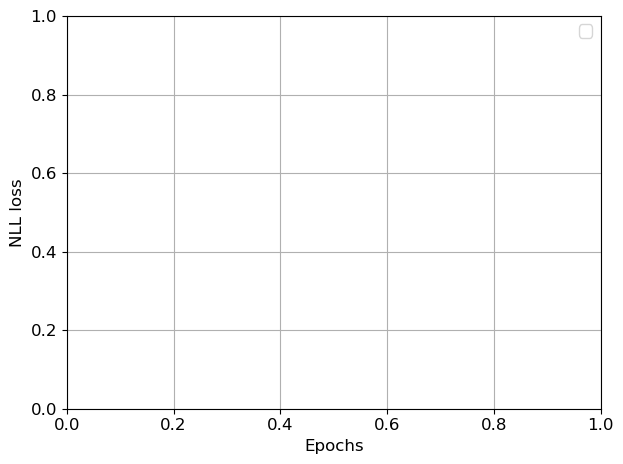

In [6]:
for i in range(len(fingerprints)):

    base_dir = '/uscms/home/jennetd/nobackup/smart-pixels/noise-paper/trained_models/model-'+fingerprints[i]+'-'+training_name+'-checkpoints/'
    
    if not os.path.exists(base_dir):
        print("Fingerprint " + fingerprints[i] + " not found")
        continue

    training_cp_path = os.path.join(base_dir, 'training_log.csv')
    training_history = pd.read_csv(training_cp_path)

    print(best_epoch[i])

    plt.plot(training_history['epoch'][:best_epoch[i]+50], training_history['loss'][:best_epoch[i]+50], linestyle='-', color=colors[0], alpha=0.75)
    plt.plot(training_history['epoch'][:best_epoch[i]+50], training_history['val_loss'][:best_epoch[i]+50], linestyle='-', color=colors[1], alpha=0.75)
    plt.plot(training_history['epoch'][:best_epoch[i]+50], (best_epoch[i]+50)*[training_history['loss'][best_epoch[i]]], linestyle='-', color=colors[0], alpha=0.75)
    
plt.legend(['training', 'validation'])
plt.grid(True)
plt.xlabel('Epochs')
plt.ylabel('NLL loss')
plt.tight_layout() 

1
2
3
4


(0.5, 100000)

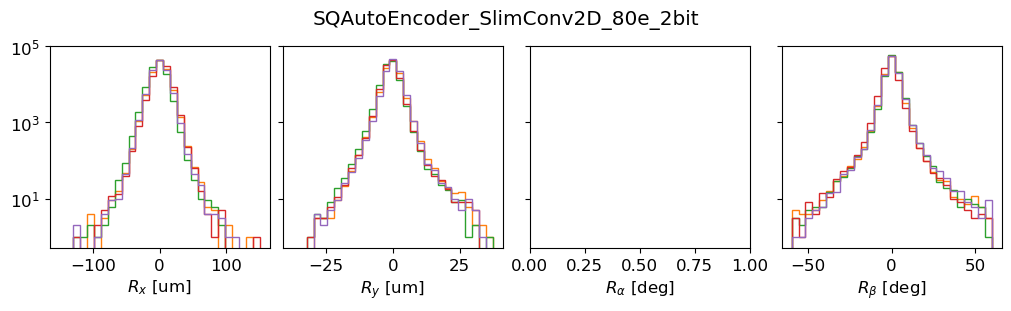

In [14]:
# OVERLAY RESIDUALS OF ALL TRAININGS --------------------------------------

# Pixel pitch (um)
xpitch = 50
ypitch = 12.5
# Thickness (um)
D = 100
# Size of pixel array
lenx = 16
leny = 16

cols = []
for v in ['x','y','B','cotB']:
    cols = cols + ['mean_'+v, 'std_'+v, 'up68_'+v, 'down68_'+v]
avg_residuals = pd.DataFrame(None, index=np.arange(len(fingerprints)),columns=cols)

fig, ax = plt.subplots(1,4,figsize=(10,3),sharey='row', constrained_layout=True)

for i,df in residuals.items():

    print(i)

    # x
    ax[0].set_xlabel(r'$R_x$ [um]')
    ax[0].hist(df["residualx"],histtype='step',bins=np.linspace(-3*xpitch,3*xpitch,30),color=colors[i])
    ax[0].set_yscale('log')

    # y
    ax[1].set_xlabel(r'$R_y$ [um]')
    ax[1].hist(df["residualy"],histtype='step',bins=np.linspace(-3*ypitch,3*ypitch,30),color=colors[i])

    # alpha
    ax[2].set_xlabel(r'$R_\alpha$ [deg]')
    #ax[2].hist(df["residualA"],histtype='step',bins=np.linspace(-60,60,30),color=colors[i])
    
    # beta
    ax[3].set_xlabel(r'$R_\beta$ [deg]')
    ax[3].hist(df["residualB"],histtype='step',bins=np.linspace(-60,60,30),color=colors[i])
      
    # Residuals for x and y (microns)
    for v in ['x','y','B','cotB']:
        # Mean
        avg_residuals['mean_'+v].iloc[i] = float(np.mean(df['residual'+v]))
        # Std -- replace with smallest window containing 68%
        avg_residuals['std_'+v].iloc[i] = float(np.std(df['residual'+v]))

        interval68 = shortest_interval_68(df['residual'+v], center_type='mean')
        avg_residuals['up68_'+v].iloc[i] = interval68['error_high']
        avg_residuals['down68_'+v].iloc[i] = interval68['error_low']

avg_residuals.to_parquet("avg_res_"+training_name+".parquet")

plt.suptitle(training_name);
ax[0].set_ylim(0.5,100000)
    
#plt.tight_layout()
#plt.savefig('plots/'+training_name+'_residuals.png')

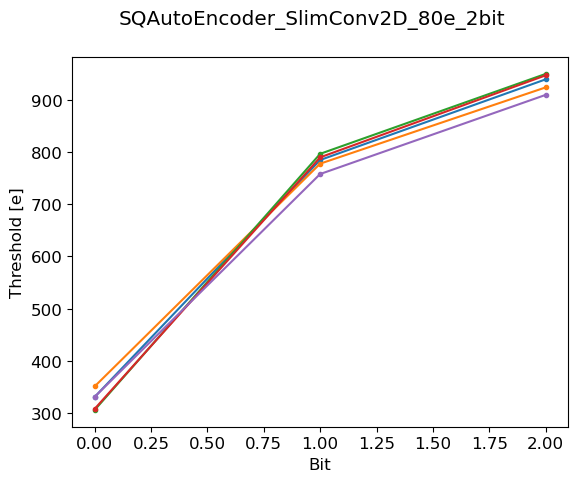

In [7]:
# OVERLAY THRESHOLDS OF ALL TRAININGS --------------------------------------

for i,df in thresholds.items():

    thr = np.array(df.iloc[best_epoch[i]].values)
    plt.plot(np.array(range(np.power(2,N_BITS)-1)), thr, linestyle='-',marker='.',label=str(i))
    
plt.xlabel('Bit')
plt.ylabel('Threshold [e]')

plt.suptitle(training_name);

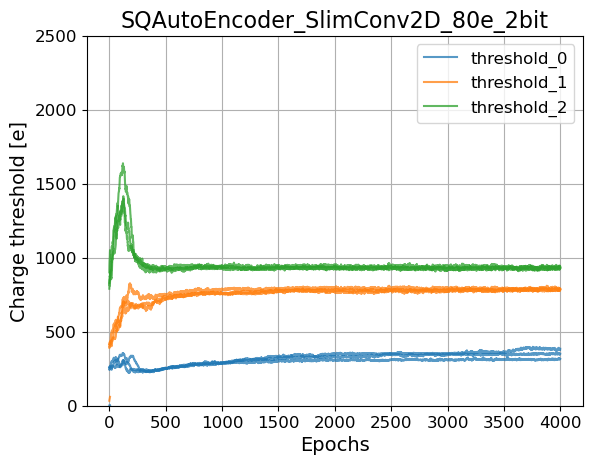

In [15]:
# THRESHOLD EVOLUTION --------------------------------------

plt.grid()


for i,df in thresholds.items():

    for i,c in enumerate(df.columns):
        epochs = df.index
        th_charge = df['threshold_'+str(i)]
        plt.plot(epochs, th_charge, linestyle='-', color=colors[i], alpha=0.75)


plt.legend([f'threshold_{i}' for i in range(3)],bbox_to_anchor=[1,1])
plt.xlabel('Epochs', fontsize =14)
plt.ylabel('Charge threshold [e]', fontsize = 14)
plt.ylim([0, 2500])
# plt.yscale('log')
plt.title(training_name, fontsize = 16);


[1721, 2660, 3397, 3405, 1710]
{1:        threshold_0  threshold_1  threshold_2
epoch                                       
0       258.882782   414.325073   829.664307
1       259.340088   416.671692   843.903564
2       261.063232   420.281372   855.074829
3       265.970642   429.153015   875.277100
4       265.045349   427.857697   873.046753
...            ...          ...          ...
3995    348.161835   782.486145   924.322388
3996    348.456146   792.647644   934.238098
3997    348.432648   789.017090   932.466064
3998    346.849670   781.848267   925.912903
3999    351.749268   787.507202   929.870056

[4000 rows x 3 columns], 3:        threshold_0  threshold_1  threshold_2
epoch                                       
0       245.185516   392.846558   791.369446
1       251.698593   403.848938   816.484131
2       252.726715   406.205566   824.550171
3       249.643036   402.032410   820.289429
4       245.243866   395.691406   811.190063
...            ...          ...     

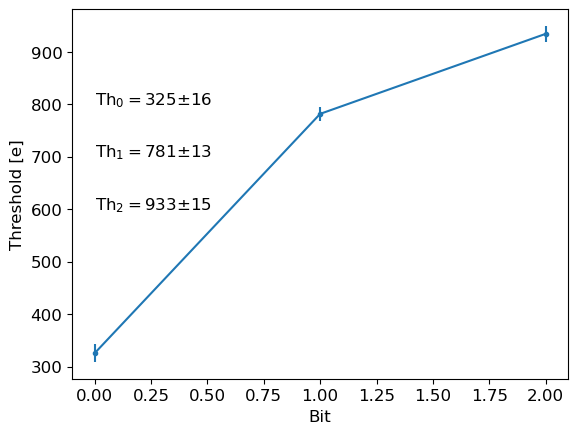

In [8]:
# AVERAGE THRESHOLDS --------------------------------------
print([best_epoch[i] for i in best_epoch.keys()])
print(thresholds)
th0 = [thresholds[i].iloc[best_epoch[i]][0] for i in best_epoch.keys()]
th1 = [thresholds[i].iloc[best_epoch[i]][1] for i in best_epoch.keys()]
th2 = [thresholds[i].iloc[best_epoch[i]][2] for i in best_epoch.keys()]

th0_mean = np.mean(th0)
th0_sigma = np.std(th0)

th1_mean = np.mean(th1)
th1_sigma = np.std(th1)

th2_mean = np.mean(th2)
th2_sigma = np.std(th2)

plt.errorbar(x=np.array(range(np.power(2,N_BITS)-1)), y=[th0_mean,th1_mean,th2_mean], yerr=[th0_sigma,th1_sigma,th2_sigma], 
             linestyle='-',marker='.',label=training_name)
    
plt.xlabel('Bit')
plt.ylabel('Threshold [e]')

plt.text(0,800,r"Th$_0=$"+str(int(th0_mean))+"$\pm$"+str(int(th0_sigma)))
plt.text(0,700,r"Th$_1=$"+str(int(th1_mean))+"$\pm$"+str(int(th1_sigma)))
plt.text(0,600,r"Th$_2=$"+str(int(th2_mean))+"$\pm$"+str(int(th2_sigma)))

data = np.array([[th0_mean,th0_sigma],[th1_mean,th1_sigma],[th2_mean,th2_sigma]])
df = pd.DataFrame(data,columns=['mean','sigma'])

df.to_parquet("avg_thr_"+training_name+".parquet")

In [10]:
# EVALUATE ON DATASET 2S

In [11]:
# DATA ---------------------------------------------------------------------

dataset_base_dir = "/uscms/home/jennetd/nobackup/smart-pixels/noise-paper/"
tfrecords_base_dir = "/uscms/home/jennetd/nobackup/smart-pixels/tfrecords"

dataset_dir_test = os.path.join(dataset_base_dir, "dataset_2s_16x16_50x12P5_centeredIncidence_parquets")
tfrecords_dir_test   = os.path.join(tfrecords_base_dir, "TFR_test",'2s_16x16_'+str(int(NOISE_SIGMA))+'eN_raw_slim')

In [12]:
seeds = grep('Seed','log_'+training_name+'.txt')
print("Seeds = ", seeds)

fingerprints = grep('Fingerprint','log_'+training_name+'.txt')
print("Fingerprints = ", fingerprints)
    
residuals = {}
thresholds = {}
best_epoch = {}

# BEGIN LOOP ---------------------------------------------------------------------
for i in range(len(fingerprints)):

    base_dir = '/uscms/home/jennetd/nobackup/smart-pixels/noise-paper/trained_models/model-'+fingerprints[i]+'-'+training_name+'-checkpoints/'
    
    if not os.path.exists(base_dir):
        print("Fingerprint " + fingerprints[i] + " not found")
        continue
        
    checkpoint_dir = base_dir + 'checkpoints/'
    checkpoint_files = [os.path.join(checkpoint_dir, f) for f in os.listdir(checkpoint_dir) if f.endswith('.hdf5')]
    #latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
    
    checkpoint_val_loss = [float(f.split('-v')[1].split('.hdf5')[0]) for f in checkpoint_files]                      
    best_checkpoint = checkpoint_files[np.argmin(checkpoint_val_loss)]
    os.system('cp '+best_checkpoint+' ' +base_dir)

    best_epoch[i] = int(best_checkpoint.split('weights.')[1].split('-t')[0])

    model = CreateSQModel_Conv2DSlim(shape = (16,16,2), 
                          n_filters=5,
                          pool_size=3)

    print(f"Loading model from {best_checkpoint}")
    model.load_weights(best_checkpoint)

    test_generator = OptimizedDataGenerator(
        load_from_tfrecords_dir= tfrecords_dir_test,
        shuffle=True,
        seed=int(seeds[i]),
        quantize=False,
    )

    sf = test_generator.labels_scale

    scale_factor = {}
    scale_factor['x'] = sf[0]
    scale_factor['y'] = sf[1]
    scale_factor['cotB'] = sf[2]

    df = construct_df_slim(model, test_generator, scale_factor, is2s = True)
    df.to_parquet(base_dir+"residuals_2s.parquet")
    residuals[i] = df


Seeds =  ['912', '656', '263', '144', '165']
Fingerprints =  ['ad44b72c', '89d11e64', '137b2874', '538f54d3', '82696c7b']
Loading model from /uscms/home/jennetd/nobackup/smart-pixels/noise-paper/trained_models/model-ad44b72c-SlimConv2D_SQ_80e_2bit-checkpoints/checkpoints/weights.2786-t43.47-v38.82.hdf5
Loading metadata from /uscms/home/jennetd/nobackup/smart-pixels/tfrecords/TFR_test/2s_16x16_80eN_raw_slim/metadata.json


278/278 [==============================] - 25s 90ms/step


100%|██████████| 278/278 [00:16<00:00, 16.95it/s]


Loading model from /uscms/home/jennetd/nobackup/smart-pixels/noise-paper/trained_models/model-89d11e64-SlimConv2D_SQ_80e_2bit-checkpoints/checkpoints/weights.1831-t43.71-v41.18.hdf5
Loading metadata from /uscms/home/jennetd/nobackup/smart-pixels/tfrecords/TFR_test/2s_16x16_80eN_raw_slim/metadata.json


278/278 [==============================] - 18s 64ms/step


...

278/278 [==============================] - 16s 57ms/step


100%|██████████| 278/278 [00:16<00:00, 16.74it/s]


Loading model from /uscms/home/jennetd/nobackup/smart-pixels/noise-paper/trained_models/model-82696c7b-SlimConv2D_SQ_80e_2bit-checkpoints/checkpoints/weights.2151-t42.95-v41.10.hdf5
Loading metadata from /uscms/home/jennetd/nobackup/smart-pixels/tfrecords/TFR_test/2s_16x16_80eN_raw_slim/metadata.json


278/278 [==============================] - 17s 59ms/step


100%|██████████| 278/278 [00:14<00:00, 18.55it/s]


0
1
2
3
4


(0.5, 10000000)

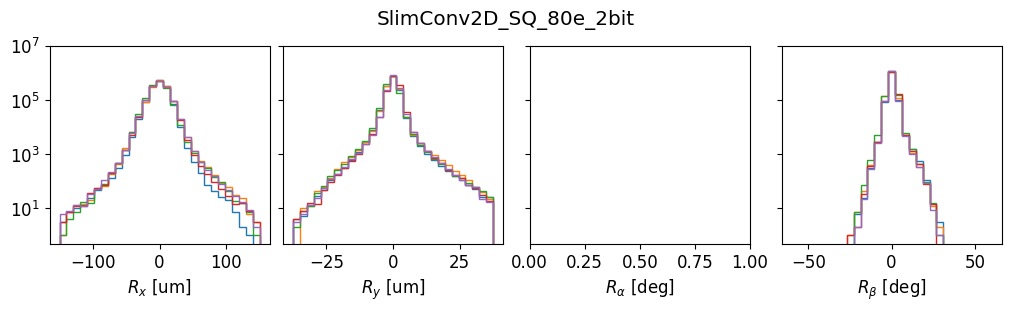

In [13]:
# OVERLAY RESIDUALS OF ALL TRAININGS --------------------------------------

# Pixel pitch (um)
xpitch = 50
ypitch = 12.5
# Thickness (um)
D = 100
# Size of pixel array
lenx = 16
leny = 16

cols = []
for v in ['x','y','A','B','cotA','cotB']:
    cols = cols + ['mean_'+v, 'std_'+v, 'up68_'+v, 'down68_'+v]
avg_residuals = pd.DataFrame(None, index=np.arange(len(fingerprints)),columns=cols)

fig, ax = plt.subplots(1,4,figsize=(10,3),sharey='row', constrained_layout=True)

for i,df in residuals.items():

    print(i)

    # x
    ax[0].set_xlabel(r'$R_x$ [um]')
    ax[0].hist(df["residualx"],histtype='step',bins=np.linspace(-3*xpitch,3*xpitch,30),color=colors[i])
    ax[0].set_yscale('log')

    # y
    ax[1].set_xlabel(r'$R_y$ [um]')
    ax[1].hist(df["residualy"],histtype='step',bins=np.linspace(-3*ypitch,3*ypitch,30),color=colors[i])

    # alpha
    ax[2].set_xlabel(r'$R_\alpha$ [deg]')
    #ax[2].hist(df["residualA"],histtype='step',bins=np.linspace(-60,60,30),color=colors[i])
    
    # beta
    ax[3].set_xlabel(r'$R_\beta$ [deg]')
    ax[3].hist(df["residualB"],histtype='step',bins=np.linspace(-60,60,30),color=colors[i])
      
    # Residuals for x and y (microns)
    for v in ['x','y','B','cotB']:
        # Mean
        avg_residuals['mean_'+v].iloc[i] = float(np.mean(df['residual'+v]))
        # Std -- replace with smallest window containing 68%
        avg_residuals['std_'+v].iloc[i] = float(np.std(df['residual'+v]))

        interval68 = shortest_interval_68(df['residual'+v], center_type='mean')
        avg_residuals['up68_'+v].iloc[i] = interval68['error_high']
        avg_residuals['down68_'+v].iloc[i] = interval68['error_low']

avg_residuals.to_parquet("avg_res_2s_"+training_name+".parquet")

plt.suptitle(training_name);
ax[0].set_ylim(0.5,10000000)
    
#plt.tight_layout()
#plt.savefig('plots/'+training_name+'_residuals.png')